# Лабораторная работа №2
## Исследование логистической и линейной регрессии

**Цель работы:** исследовать алгоритмы логистической регрессии для классификации и линейной регрессии для регрессионной задачи; построить базовые и улучшенные модели, самостоятельно реализовать алгоритмы и сравнить результаты

**Датасеты (те же, что в ЛР1):**
- **Классификация:** Breast Cancer Wisconsin (Diagnostic), бинарная классификация злокачественных и доброкачественных опухолей
- **Регрессия:** Wine Quality (Red), прогнозирование численной оценки качества вина

## 1. Постановка задач и метрики

### 1.1. Классификация - Breast Cancer Wisconsin
Целевая переменная: `0` - malignant (злокачественная опухоль), `1` - benign (доброкачественная опухоль)

Метрики:
- **Accuracy** - доля верных предсказаний
- **F1-score (binary)** - гармоническое среднее Precision и Recall для класса `1`
- **F1 macro** - среднее F1 по двум классам
- **Recall malignant** и **F1 malignant** - отдельно оценивают обнаружение злокачественных опухолей
- **ROC-AUC** - качество ранжирования объектов по вероятности класса `1`
- **Confusion Matrix** - показывает типы ошибок

### 1.2. Регрессия - Wine Quality (Red)
Целевая переменная: `quality`

Метрики:
- **MAE** - средняя абсолютная ошибка, в единицах целевой переменной
- **RMSE** - корень из среднеквадратичной ошибки, сильнее штрафует большие ошибки
- **R²** - доля объяснённой моделью дисперсии

В этой ячейке импортируются библиотеки для обработки данных, визуализации, обучения моделей, кросс-валидации и расчёта метрик. Фиксируется `RANDOM_STATE`, чтобы разбиение данных и эксперименты были воспроизводимыми.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, recall_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    RocCurveDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

Загружаются 2 набора данных. Для Breast Cancer используется встроенный датасет `scikit-learn`; Wine Quality загружается из репозитория UCI. Затем выводятся размеры таблиц и распределения целевых переменных для первичной проверки данных

In [2]:
cancer = load_breast_cancer()
X_clf = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_clf = pd.Series(cancer.target, name="target")

url_wine = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_wine = pd.read_csv(url_wine, sep=";")
X_reg = df_wine.drop(columns="quality")
y_reg = df_wine["quality"]

print("Breast Cancer:", X_clf.shape)
print("Классы (0=malignant, 1=benign):", y_clf.value_counts().sort_index().to_dict())
print("Wine Quality:", X_reg.shape)
print("Распределение quality:")
print(y_reg.value_counts().sort_index())

Breast Cancer: (569, 30)
Классы (0=malignant, 1=benign): {0: 212, 1: 357}
Wine Quality: (1599, 11)
Распределение quality:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


Визуализация показывает распределение классов в задаче классификации и распределение оценок качества вина в задаче регрессии. Это помогает выявить дисбаланс классов и неравномерность целевой переменной

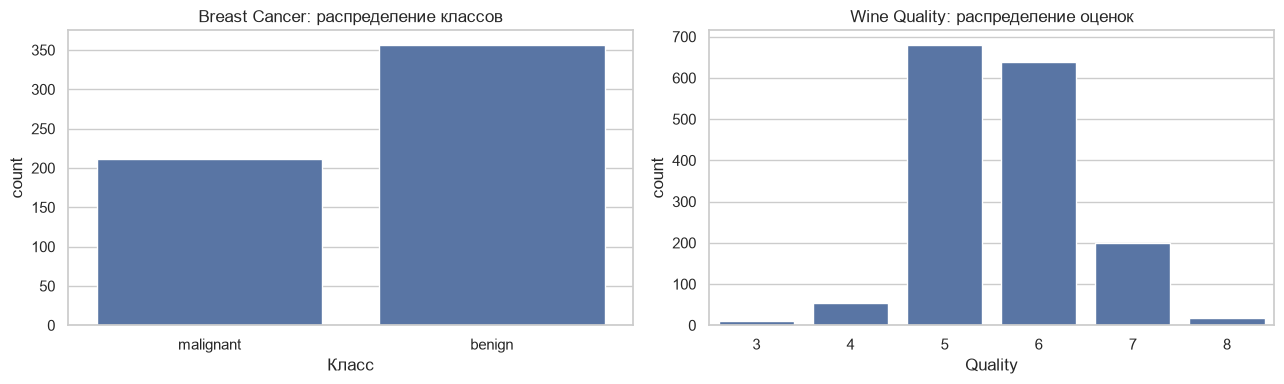

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y_clf.map({0: "malignant", 1: "benign"}), ax=axes[0])
axes[0].set_title("Breast Cancer: распределение классов")
axes[0].set_xlabel("Класс")

sns.countplot(x=y_reg, ax=axes[1])
axes[1].set_title("Wine Quality: распределение оценок")
axes[1].set_xlabel("Quality")
plt.tight_layout()
plt.show()

## 2. Разделение данных на обучающую и тестовую выборки

Данные разделяются на обучающую и тестовую выборки в пропорции 80/20. Для классификации применяется стратификация, чтобы сохранить соотношение malignant/benign в обеих выборках. Тестовые данные не используются при подборе гиперпараметров

In [4]:
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

print("Classification:", X_clf_train.shape, X_clf_test.shape)
print("Regression:", X_reg_train.shape, X_reg_test.shape)

Classification: (455, 30) (114, 30)
Regression: (1279, 11) (320, 11)


## 3. Создание baseline и оценка качества

### 3.1. Логистическая регрессия - baseline

Обучается базовая модель `LogisticRegression` без дополнительного масштабирования и подбора гиперпараметров. После обучения рассчитываются вероятности и предсказания на тестовой выборке, затем вычисляются основные метрики классификации

In [5]:
log_clf_base = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
log_clf_base.fit(X_clf_train, y_clf_train)

y_clf_pred_base = log_clf_base.predict(X_clf_test)
y_clf_proba_base = log_clf_base.predict_proba(X_clf_test)[:, 1]

acc_clf_base = accuracy_score(y_clf_test, y_clf_pred_base)
f1_clf_base = f1_score(y_clf_test, y_clf_pred_base)
f1_macro_clf_base = f1_score(y_clf_test, y_clf_pred_base, average="macro")
roc_clf_base = roc_auc_score(y_clf_test, y_clf_proba_base)
recall_mal_base = recall_score(y_clf_test, y_clf_pred_base, pos_label=0)
f1_mal_base = f1_score(y_clf_test, y_clf_pred_base, pos_label=0)

print("Logistic Regression - baseline")
print(f"Accuracy: {acc_clf_base:.4f}")
print(f"F1 (binary): {f1_clf_base:.4f}")
print(f"F1 macro: {f1_macro_clf_base:.4f}")
print(f"ROC-AUC: {roc_clf_base:.4f}")
print(f"Recall malignant: {recall_mal_base:.4f}")
print(f"F1 malignant: {f1_mal_base:.4f}")
print("\\nClassification report:")
print(classification_report(y_clf_test, y_clf_pred_base, target_names=["malignant", "benign"]))

Logistic Regression - baseline
Accuracy: 0.9649
F1 (binary): 0.9726
F1 macro: 0.9619
ROC-AUC: 0.9954
Recall malignant: 0.9286
F1 malignant: 0.9512
\nClassification report:
              precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### 3.2. Линейная регрессия - baseline

Обучается базовая модель `LinearRegression` на исходных признаках без масштабирования и преобразования. Качество оценивается на тестовой выборке с помощью MAE, RMSE и R^2

In [6]:
lin_reg_base = LinearRegression()
lin_reg_base.fit(X_reg_train, y_reg_train)
y_reg_pred_base = lin_reg_base.predict(X_reg_test)

mae_reg_base = mean_absolute_error(y_reg_test, y_reg_pred_base)
rmse_reg_base = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_base))
r2_reg_base = r2_score(y_reg_test, y_reg_pred_base)

print("Linear Regression - baseline")
print(f"MAE: {mae_reg_base:.4f}")
print(f"RMSE: {rmse_reg_base:.4f}")
print(f"R^2: {r2_reg_base:.4f}")

Linear Regression - baseline
MAE: 0.5035
RMSE: 0.6245
R^2: 0.4032


### 3.3. Визуализация baseline

Строятся матрица ошибок для классификации и график "фактические значения - предсказания" для регрессии. Для идеального регрессионного прогноза точки располагались бы на диагонали `y = x`

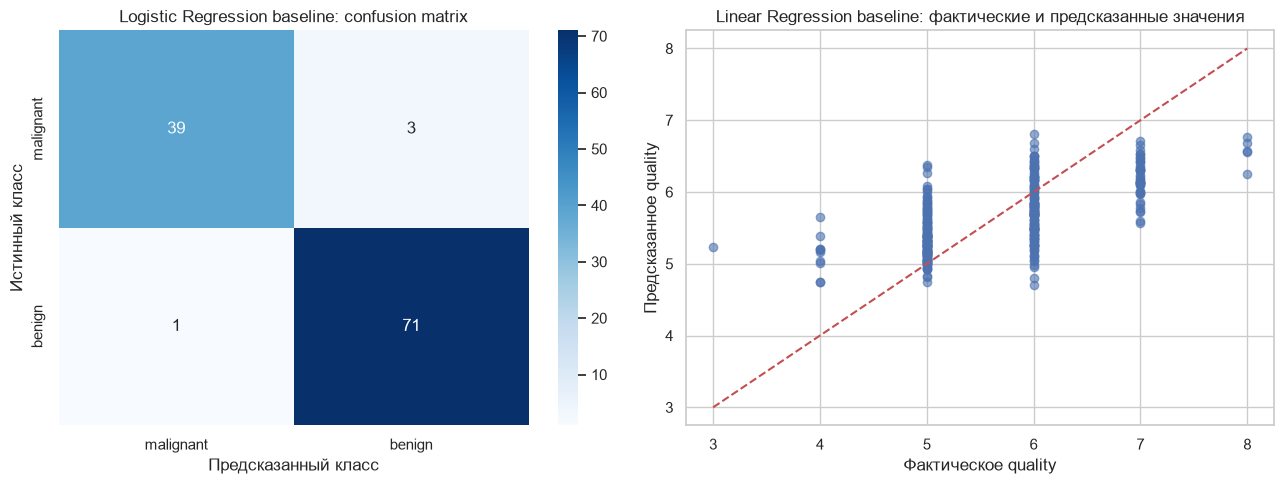

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_clf_test, y_clf_pred_base)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
axes[0].set_title("Logistic Regression baseline: confusion matrix")
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")

axes[1].scatter(y_reg_test, y_reg_pred_base, alpha=0.6)
lims = [min(y_reg_test.min(), y_reg_pred_base.min()), max(y_reg_test.max(), y_reg_pred_base.max())]
axes[1].plot(lims, lims, "r--")
axes[1].set_title("Linear Regression baseline: фактические и предсказанные значения")
axes[1].set_xlabel("Фактическое quality")
axes[1].set_ylabel("Предсказанное quality")
plt.tight_layout()
plt.show()

## 4. Улучшение baseline

### 4.1. Гипотезы улучшения

**Для логистической регрессии:**
1. Масштабирование признаков через `StandardScaler` может улучшить оптимизацию и сделать регуляризацию сопоставимой для признаков разных масштабов
2. Подбор коэффициента регуляризации `C` может улучшить обобщающую способность
3. Параметр `class_weight` (`None` или `balanced`) позволяет проверить влияние компенсации дисбаланса классов

**Для линейной регрессии:**
1. Стандартизация признаков может улучшить численную устойчивость вычислений
2. Добавление полиномиальных признаков второй степени может выявить нелинейные зависимости между химическими характеристиками и качеством вина

Все преобразования включаются в `Pipeline`, чтобы они обучались отдельно внутри каждого фолда кросс-валидации и не возникала утечка данных

### 4.2. Подбор гиперпараметров логистической регрессии

Создаётся конвейер из `StandardScaler` и `LogisticRegression`. `GridSearchCV` перебирает значения `C` и варианты `class_weight`; качество оценивается по `F1 macro` на пяти фолдах. Тестовая выборка остаётся отложенной до финальной оценки

In [8]:
pipe_log_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

param_grid_log_clf = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

grid_log_clf = GridSearchCV(
    pipe_log_clf, param_grid_log_clf, cv=5,
    scoring="f1_macro", n_jobs=-1, refit=True
)
grid_log_clf.fit(X_clf_train, y_clf_train)

print("Best parameters:", grid_log_clf.best_params_)
print(f"Best CV F1-macro: {grid_log_clf.best_score_:.4f}")
log_clf_improved = grid_log_clf.best_estimator_

y_clf_pred_imp = log_clf_improved.predict(X_clf_test)
y_clf_proba_imp = log_clf_improved.predict_proba(X_clf_test)[:, 1]

acc_clf_imp = accuracy_score(y_clf_test, y_clf_pred_imp)
f1_clf_imp = f1_score(y_clf_test, y_clf_pred_imp)
f1_macro_clf_imp = f1_score(y_clf_test, y_clf_pred_imp, average="macro")
roc_clf_imp = roc_auc_score(y_clf_test, y_clf_proba_imp)
recall_mal_imp = recall_score(y_clf_test, y_clf_pred_imp, pos_label=0)
f1_mal_imp = f1_score(y_clf_test, y_clf_pred_imp, pos_label=0)

print(f"Test Accuracy: {acc_clf_imp:.4f}")
print(f"Test F1 binary: {f1_clf_imp:.4f}")
print(f"Test F1 macro: {f1_macro_clf_imp:.4f}")
print(f"Test ROC-AUC: {roc_clf_imp:.4f}")
print(f"Recall malignant: {recall_mal_imp:.4f}")
print(f"F1 malignant: {f1_mal_imp:.4f}")

Best parameters: {'model__C': 1, 'model__class_weight': None}
Best CV F1-macro: 0.9787
Test Accuracy: 0.9825
Test F1 binary: 0.9861
Test F1 macro: 0.9812
Test ROC-AUC: 0.9954
Recall malignant: 0.9762
F1 malignant: 0.9762


### 4.3. Подбор конфигурации линейной регрессии

Проверяется гипотеза о пользе полиномиальных признаков второй степени. `PolynomialFeatures` и `StandardScaler` находятся внутри конвейера, поэтому все параметры преобразования оцениваются корректно в кросс-валидации. Подбор выполняется по MAE: чем меньше MAE, тем лучше

In [9]:
pipe_lin_reg = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

param_grid_lin_reg = {
    "poly__degree": [1, 2]
}

grid_lin_reg = GridSearchCV(
    pipe_lin_reg, param_grid_lin_reg, cv=5,
    scoring="neg_mean_absolute_error", n_jobs=-1, refit=True
)
grid_lin_reg.fit(X_reg_train, y_reg_train)

print("Best parameters:", grid_lin_reg.best_params_)
print(f"Best CV MAE: {-grid_lin_reg.best_score_:.4f}")
lin_reg_improved = grid_lin_reg.best_estimator_

y_reg_pred_imp = lin_reg_improved.predict(X_reg_test)
mae_reg_imp = mean_absolute_error(y_reg_test, y_reg_pred_imp)
rmse_reg_imp = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_imp))
r2_reg_imp = r2_score(y_reg_test, y_reg_pred_imp)

print(f"Test MAE:  {mae_reg_imp:.4f}")
print(f"Test RMSE: {rmse_reg_imp:.4f}")
print(f"Test R²:   {r2_reg_imp:.4f}")

Best parameters: {'poly__degree': 1}
Best CV MAE: 0.5072
Test MAE:  0.5035
Test RMSE: 0.6245
Test R²:   0.4032


### 4.4. Сравнение baseline и improved baseline

Результаты базовых и улучшенных моделей сравниваются на одной и той же тестовой выборке. Таблицы позволяют оценить, дали ли масштабирование, регуляризация и полиномиальные признаки практический прирост качества

In [10]:
clf_baseline_vs_improved = pd.DataFrame([
    {"Модель": "Logistic Regression baseline", "Accuracy": acc_clf_base,
     "F1 binary": f1_clf_base, "F1 macro": f1_macro_clf_base,
     "ROC-AUC": roc_clf_base, "Recall malignant": recall_mal_base,
     "F1 malignant": f1_mal_base},
    {"Модель": "Logistic Regression improved", "Accuracy": acc_clf_imp,
     "F1 binary": f1_clf_imp, "F1 macro": f1_macro_clf_imp,
     "ROC-AUC": roc_clf_imp, "Recall malignant": recall_mal_imp,
     "F1 malignant": f1_mal_imp}
])

reg_baseline_vs_improved = pd.DataFrame([
    {"Модель": "Linear Regression baseline", "MAE": mae_reg_base,
     "RMSE": rmse_reg_base, "R^2": r2_reg_base},
    {"Модель": "Linear Regression improved", "MAE": mae_reg_imp,
     "RMSE": rmse_reg_imp, "R^2": r2_reg_imp}
])

display(clf_baseline_vs_improved.round(4))
display(reg_baseline_vs_improved.round(4))

,Модель,Accuracy,F1 binary,F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,Logistic Regression baseline,0.9649,0.9726,0.9619,0.9954,0.9286,0.9512
1,Logistic Regression improved,0.9825,0.9861,0.9812,0.9954,0.9762,0.9762


,Модель,MAE,RMSE,R^2
0,Linear Regression baseline,0.5035,0.6245,0.4032
1,Linear Regression improved,0.5035,0.6245,0.4032


### 4.5. Визуализация улучшенных моделей

Строятся ROC-кривые baseline и improved логистической регрессии, а также матрица ошибок улучшенной модели. Для регрессии сравниваются фактические и предсказанные значения улучшенной модели

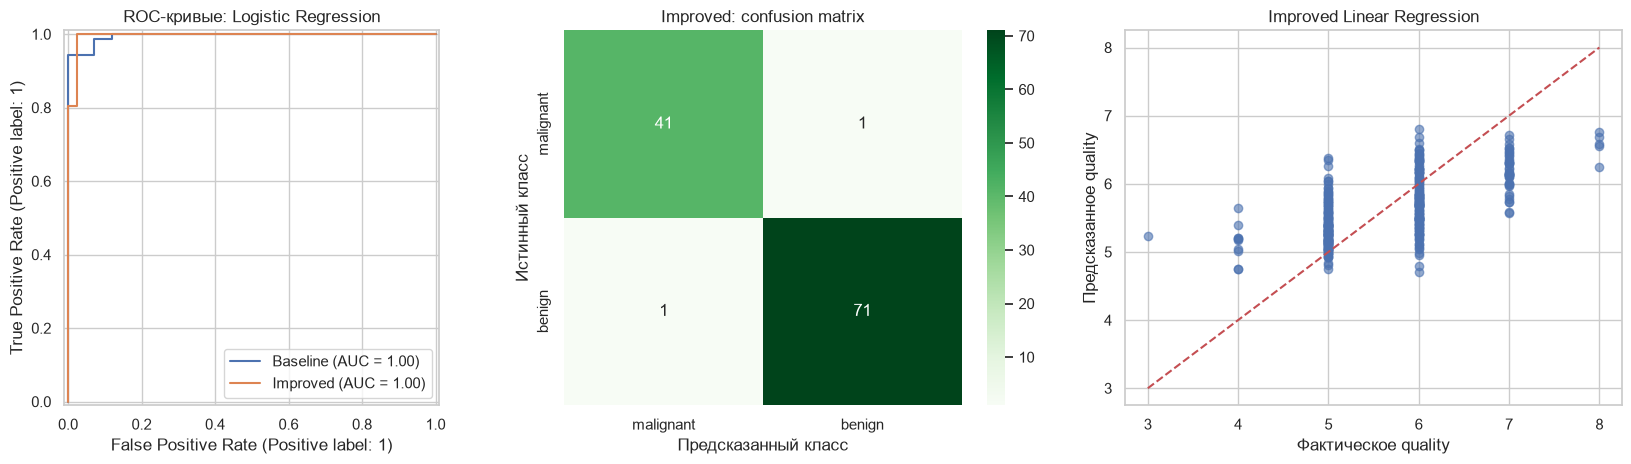

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_base, name="Baseline", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_imp, name="Improved", ax=axes[0])
axes[0].set_title("ROC-кривые: Logistic Regression")

cm_imp = confusion_matrix(y_clf_test, y_clf_pred_imp)
sns.heatmap(cm_imp, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
axes[1].set_title("Improved: confusion matrix")
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")

axes[2].scatter(y_reg_test, y_reg_pred_imp, alpha=0.6)
lims = [min(y_reg_test.min(), y_reg_pred_imp.min()), max(y_reg_test.max(), y_reg_pred_imp.max())]
axes[2].plot(lims, lims, "r--")
axes[2].set_title("Improved Linear Regression")
axes[2].set_xlabel("Фактическое quality")
axes[2].set_ylabel("Предсказанное quality")
plt.tight_layout()
plt.show()

## 5. Самостоятельная имплементация алгоритмов

В этом разделе реализуются два алгоритма без использования готовых классов `LogisticRegression` и `LinearRegression` для обучения

- **MyLogisticRegression:** логистическая регрессия с сигмоидой и градиентным спуском по log-loss; поддерживается L2-регуляризация
- **MyLinearRegression:** линейная регрессия с градиентным спуском по MSE; коэффициенты обновляются итеративно

Для проверки корректности сначала обучаются собственные реализации на исходных признаках, затем — на масштабированных признаках. В улучшенной версии логистической регрессии используется найденное значение `C`; в собственной линейной регрессии проверяется конфигурация признаков, выбранная для improved baseline

Реализуется логистическая регрессия. В `fit` добавляется свободный член, рассчитывается сигмоида и минимизируется log-loss с L2-регуляризацией коэффициентов (свободный член не регуляризуется). `predict_proba` возвращает вероятности двух классов, `predict` использует порог 0.5

In [12]:
class MyLogisticRegression:
    def __init__(self, learning_rate=0.05, n_iter=5000, C=1.0):
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.C = C
        self.weights = None
        self.loss_history = []

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        self.weights = np.zeros(X_bias.shape[1])
        reg_strength = 1.0 / max(self.C, 1e-12)
        n = len(y)

        for _ in range(self.n_iter):
            probabilities = self._sigmoid(X_bias @ self.weights)
            error = probabilities - y
            gradient = (X_bias.T @ error) / n
            gradient[1:] += reg_strength * self.weights[1:] / n
            self.weights -= self.learning_rate * gradient

            eps = 1e-12
            loss = -np.mean(y * np.log(probabilities + eps) + (1-y) * np.log(1-probabilities + eps))
            loss += reg_strength * np.sum(self.weights[1:] ** 2) / (2*n)
            self.loss_history.append(loss)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        p1 = self._sigmoid(X_bias @ self.weights)
        return np.c_[1-p1, p1]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

Реализуется линейная регрессия с градиентным спуском. Оптимизируется среднеквадратичная ошибка; свободный член не штрафуется. Параметры модели и история функции потерь сохраняются после обучения

In [13]:
class MyLinearRegression:
    def __init__(self, learning_rate=0.03, n_iter=6000):
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.weights = None
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        self.weights = np.zeros(X_bias.shape[1])
        n = len(y)

        for _ in range(self.n_iter):
            predictions = X_bias @ self.weights
            error = predictions - y
            gradient = (2 / n) * (X_bias.T @ error)
            self.weights -= self.learning_rate * gradient
            self.loss_history.append(np.mean(error ** 2))
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        return X_bias @ self.weights

### 5.1. Собственные модели без улучшений (raw)

Собственные реализации обучаются на исходных признаках. Для классификации рассчитываются Accuracy, F1, ROC-AUC и медицинские метрики; для регрессии — MAE, RMSE и R^2. Это позволяет сравнить собственные алгоритмы с baseline sklearn

In [14]:
my_log_clf_raw = MyLogisticRegression(learning_rate=1e-7, n_iter=10000, C=1.0)
my_log_clf_raw.fit(X_clf_train, y_clf_train)
y_clf_pred_my_raw = my_log_clf_raw.predict(X_clf_test)
y_clf_proba_my_raw = my_log_clf_raw.predict_proba(X_clf_test)[:, 1]

my_acc_raw = accuracy_score(y_clf_test, y_clf_pred_my_raw)
my_f1_raw = f1_score(y_clf_test, y_clf_pred_my_raw)
my_f1_macro_raw = f1_score(y_clf_test, y_clf_pred_my_raw, average="macro")
my_roc_raw = roc_auc_score(y_clf_test, y_clf_proba_my_raw)
my_recall_mal_raw = recall_score(y_clf_test, y_clf_pred_my_raw, pos_label=0)
my_f1_mal_raw = f1_score(y_clf_test, y_clf_pred_my_raw, pos_label=0)

my_lin_reg_raw = MyLinearRegression(learning_rate=0.000001, n_iter=6000)
my_lin_reg_raw.fit(X_reg_train, y_reg_train)
y_reg_pred_my_raw = my_lin_reg_raw.predict(X_reg_test)
my_mae_raw = mean_absolute_error(y_reg_test, y_reg_pred_my_raw)
my_rmse_raw = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_raw))
my_r2_raw = r2_score(y_reg_test, y_reg_pred_my_raw)

print("My Logistic Regression raw:", my_acc_raw, my_f1_raw, my_roc_raw)
print("Recall/F1 malignant:", my_recall_mal_raw, my_f1_mal_raw)
print("My Linear Regression raw:", my_mae_raw, my_rmse_raw, my_r2_raw)

My Logistic Regression raw: 0.9035087719298246 0.9251700680272109 0.9193121693121693
Recall/F1 malignant: 0.8333333333333334 0.8641975308641975
My Linear Regression raw: 1.3771927435071933 1.629552992054762 -3.0633804820881645


### 5.2. Собственные модели с техниками улучшенного baseline

Масштабирование обучается только на train и применяется к test. Для логистической регрессии используется найденный GridSearchCV параметр `C`. Для линейной регрессии повторяется преобразование признаков (полиномиальные признаки выбранной степени и масштабирование), после чего обучается собственная модель градиентным спуском

In [15]:
scaler_my_clf = StandardScaler()
X_clf_train_sc = scaler_my_clf.fit_transform(X_clf_train)
X_clf_test_sc = scaler_my_clf.transform(X_clf_test)
best_C = grid_log_clf.best_params_["model__C"]

my_log_clf_imp = MyLogisticRegression(learning_rate=0.05, n_iter=7000, C=best_C)
my_log_clf_imp.fit(X_clf_train_sc, y_clf_train)
y_clf_pred_my_imp = my_log_clf_imp.predict(X_clf_test_sc)
y_clf_proba_my_imp = my_log_clf_imp.predict_proba(X_clf_test_sc)[:, 1]

my_acc_imp = accuracy_score(y_clf_test, y_clf_pred_my_imp)
my_f1_imp = f1_score(y_clf_test, y_clf_pred_my_imp)
my_f1_macro_imp = f1_score(y_clf_test, y_clf_pred_my_imp, average="macro")
my_roc_imp = roc_auc_score(y_clf_test, y_clf_proba_my_imp)
my_recall_mal_imp = recall_score(y_clf_test, y_clf_pred_my_imp, pos_label=0)
my_f1_mal_imp = f1_score(y_clf_test, y_clf_pred_my_imp, pos_label=0)


best_degree = grid_lin_reg.best_params_["poly__degree"]
poly_my = PolynomialFeatures(degree=best_degree, include_bias=False)
X_reg_train_poly = poly_my.fit_transform(X_reg_train)
X_reg_test_poly = poly_my.transform(X_reg_test)
scaler_my_reg = StandardScaler()
X_reg_train_sc = scaler_my_reg.fit_transform(X_reg_train_poly)
X_reg_test_sc = scaler_my_reg.transform(X_reg_test_poly)

my_lin_reg_imp = MyLinearRegression(learning_rate=0.01, n_iter=10000)
my_lin_reg_imp.fit(X_reg_train_sc, y_reg_train)
y_reg_pred_my_imp = my_lin_reg_imp.predict(X_reg_test_sc)
my_mae_imp = mean_absolute_error(y_reg_test, y_reg_pred_my_imp)
my_rmse_imp = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_imp))
my_r2_imp = r2_score(y_reg_test, y_reg_pred_my_imp)

print("My Logistic Regression improved:", my_acc_imp, my_f1_imp, my_roc_imp)
print("Recall/F1 malignant:", my_recall_mal_imp, my_f1_mal_imp)
print("My Linear Regression improved:", my_mae_imp, my_rmse_imp, my_r2_imp)

My Logistic Regression improved: 0.9824561403508771 0.9861111111111112 0.9957010582010581
Recall/F1 malignant: 0.9761904761904762 0.9761904761904762
My Linear Regression improved: 0.5035304408950806 0.6245199280773557 0.40318034647958967


## 6. Сравнение всех моделей

Формируются итоговые таблицы для классификации и регрессии. Сравниваются baseline sklearn, improved sklearn, собственная реализация без улучшений и собственная реализация с улучшениями. Значения рассчитываются на одном тестовом разбиении

In [16]:
classification_results = pd.DataFrame([
    ["sklearn baseline", acc_clf_base, f1_clf_base, f1_macro_clf_base, roc_clf_base, recall_mal_base, f1_mal_base],
    ["sklearn improved", acc_clf_imp, f1_clf_imp, f1_macro_clf_imp, roc_clf_imp, recall_mal_imp, f1_mal_imp],
    ["MyLogisticRegression raw", my_acc_raw, my_f1_raw, my_f1_macro_raw, my_roc_raw, my_recall_mal_raw, my_f1_mal_raw],
    ["MyLogisticRegression improved", my_acc_imp, my_f1_imp, my_f1_macro_imp, my_roc_imp, my_recall_mal_imp, my_f1_mal_imp]
], columns=["Модель", "Accuracy", "F1 binary", "F1 macro", "ROC-AUC", "Recall malignant", "F1 malignant"])

regression_results = pd.DataFrame([
    ["sklearn baseline", mae_reg_base, rmse_reg_base, r2_reg_base],
    ["sklearn improved", mae_reg_imp, rmse_reg_imp, r2_reg_imp],
    ["MyLinearRegression raw", my_mae_raw, my_rmse_raw, my_r2_raw],
    ["MyLinearRegression improved", my_mae_imp, my_rmse_imp, my_r2_imp]
], columns=["Модель", "MAE", "RMSE", "R^2"])

display(classification_results.round(4))
display(regression_results.round(4))

,Модель,Accuracy,F1 binary,F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,sklearn baseline,0.9649,0.9726,0.9619,0.9954,0.9286,0.9512
1,sklearn improved,0.9825,0.9861,0.9812,0.9954,0.9762,0.9762
2,MyLogisticRegression raw,0.9035,0.9252,0.8947,0.9193,0.8333,0.8642
3,MyLogisticRegression improved,0.9825,0.9861,0.9812,0.9957,0.9762,0.9762


,Модель,MAE,RMSE,R^2
0,sklearn baseline,0.5035,0.6245,0.4032
1,sklearn improved,0.5035,0.6245,0.4032
2,MyLinearRegression raw,1.3772,1.6296,-3.0634
3,MyLinearRegression improved,0.5035,0.6245,0.4032


Графики позволяют визуально сравнить качество моделей: ROC-кривые для классификации и столбчатые диаграммы основных метрик для обеих задач. Для MAE и RMSE меньшие значения лучше, для Accuracy, F1 и ROC-AUC - большие

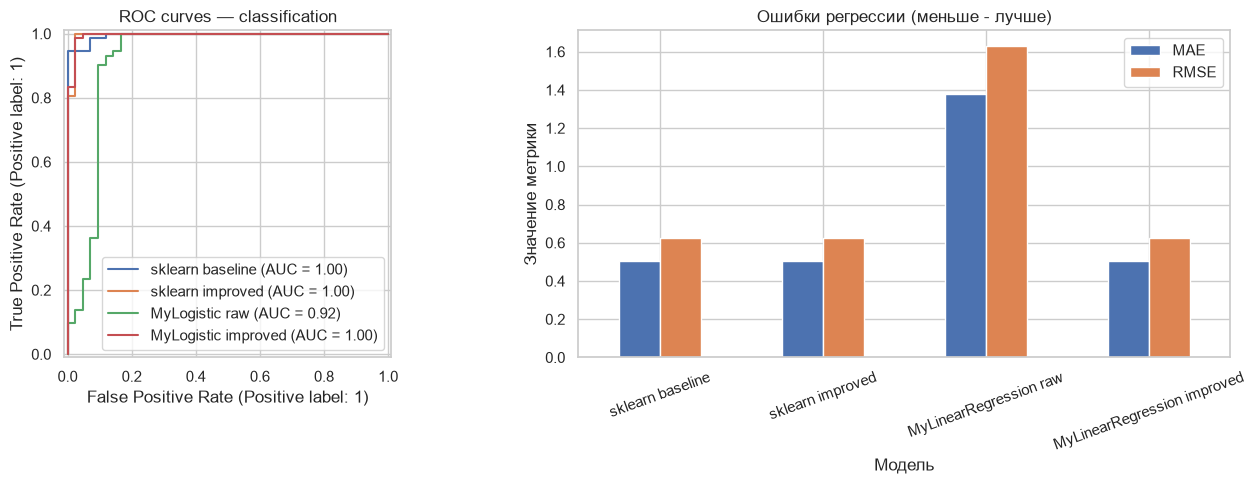

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_base, name="sklearn baseline", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_imp, name="sklearn improved", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_my_raw, name="MyLogistic raw", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_my_imp, name="MyLogistic improved", ax=axes[0])
axes[0].set_title("ROC curves — classification")

regression_results.set_index("Модель")[["MAE", "RMSE"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Ошибки регрессии (меньше - лучше)")
axes[1].set_ylabel("Значение метрики")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. Выводы

В лабораторной работе были исследованы логистическая регрессия для классификации и линейная регрессия для регрессии на тех же наборах данных, что и в ЛР1: Breast Cancer Wisconsin (Diagnostic) и Wine Quality (Red). Для каждой задачи были построены базовая и улучшенная модели scikit-learn, а также реализованы собственные версии алгоритмов на основе градиентного спуска.

### 7.1. Логистическая регрессия

**Базовая модель LogisticRegression показала высокое качество:** Accuracy = 0.9649, F1 macro = 0.9619 и ROC-AUC = 0.9954. После масштабирования признаков и подбора гиперпараметров (C=1, class_weight=None) Accuracy выросла до 0.9825, F1 macro - до 0.9812. ROC-AUC остался на уровне 0.9954

**Особенно важен результат для класса malignant:** Recall увеличился с 0.9286 до 0.9762, а F1 - с 0.9512 до 0.9762. Таким образом, улучшенная модель обнаруживает 41 из 42 злокачественных случаев тестовой выборки вместо 39 из 42 у baseline. Для задачи медицинской диагностики это более содержательный результат, чем одно только увеличение Accuracy

Подбор параметров выполнялся с помощью пятиблочной кросс-валидации по F1 macro. Лучшее среднее значение CV F1 macro составило 0.9787. Использование Pipeline обеспечило выполнение масштабирования отдельно внутри каждого фолда и исключило утечку информации из валидационных фолдов

### 7.2. Линейная регрессия

Базовая линейная регрессия показала MAE = 0.5035, RMSE = 0.6245 и R^2 = 0.4032. В ходе подбора конфигурации проверялись полиномиальные признаки первой и второй степени. GridSearchCV выбрал degree=1; среднее CV MAE составило 0.5072

На тестовой выборке улучшенная модель получила те же значения MAE, RMSE и R^2, что и baseline. Следовательно, в данном эксперименте добавление полиномиальных признаков второй степени не улучшило качество по выбранной метрике MAE. Это является допустимым исследовательским результатом: проверенная гипотеза не подтвердилась. Стандартизация признаков для обычной линейной регрессии без регуляризации также не обязана менять предсказания, поскольку сама по себе не добавляет модели новых степеней свободы

Значение R^2 = 0.4032 указывает на умеренную объясняющую способность линейной модели: часть зависимости качества вина от физико-химических характеристик остаётся неописанной линейной комбинацией признаков

### 7.3. Собственные реализации алгоритмов

Собственные реализации с масштабированием показали результаты, близкие к моделям scikit-learn:

- MyLogisticRegression improved: Accuracy = 0.9825, F1 binary = 0.9861, F1 macro = 0.9812, ROC-AUC = 0.9957, Recall malignant = 0.9762

- MyLinearRegression improved: MAE = 0.5035, RMSE = 0.6245, R^2 = 0.4032.
Это подтверждает корректность реализованных функций предсказания и возможность обучения собственных моделей градиентным спуском на подготовленных признаках

Собственные модели без масштабирования показали заметно худшие результаты: для логистической регрессии Accuracy = 0.9035 и ROC-AUC = 0.9193; для линейной регрессии MAE = 1.3772, RMSE = 1.6296 и R^2 = -3.0634. Такие результаты указывают прежде всего на проблемы сходимости выбранного градиентного спуска на признаках разных масштабов при заданных фиксированных скоростях обучения. Отрицательный R^2 означает, что полученная собственная линейная модель на этой тестовой выборке предсказывает хуже простого прогноза средним значением целевой переменной

Поэтому результаты raw-реализаций следует интерпрретировать как демонстрацию чувствительности градиентного спуска к масштабу признаков и настройке скорости обучения, а не как доказательство того, что сами алгоритмы логистической или линейной регрессии обязательно хуже работают без стандартизации

### 7.4. Итог

1. Для задачи классификации логистическая регрессия показала высокое качество уже в базовой конфигурации. Масштабирование и подбор гиперпараметров дали дополнительный прирост, особенно по Recall и F1 для класса malignant

2. Для задачи регрессии линейная модель достигла умеренного качества. Полиномиальные признаки второй степени не дали улучшения на выбранном разбиении и по критерию MAE

3. Собственные реализации после масштабирования воспроизвели результаты библиотечных моделей с небольшой разницей, что подтверждает работоспособность реализованных алгоритмов

4. Эксперименты с собственными моделями на исходных признаках показали важность выбора подходящей скорости обучения и контроля сходимости градиентного спуска

5. По сравнению с ЛР1, улучшенная логистическая регрессия показала более высокие метрики классификации, чем улучшенный KNN. В задаче регрессии улучшенный KNN из ЛР1 оказался точнее линейной регрессии по всем трём использованным метрикам. Это сравнение корректно интерпретировать при условии одинакового разбиения train/test в обеих лабораторных работах


Таким образом, цель лабораторной работы достигнута: построены и оценены baseline- и improved-модели, реализованы собственные алгоритмы, выполнено сравнение результатов и проверены гипотезы об улучшении качества